# 00 Overview: a delay-line neural network, simulated at four fidelities

**One trained network, four levels of physical realism.** The network is a *ternary tapped-delay-line convolution net* (TDL-Net): every layer is a bank of coax delay lines with taps, a passive combiner, and a saturating amplifier. The weights are only ever **-1, 0, +1**, so a weight is literally *a tap polarity*. The task is 8-class modulation recognition (OOK, BPSK, QPSK, 8PSK, 16QAM, 2FSK, 4FSK, GMSK) on synthetic I/Q at 0-20 dB SNR.

For layer $l$ with input lines $i$, output lines $o$, $K$ taps, dilation $d_l$ and symbol period $T_s=10\,\mathrm{ns}$:

$$u_o[n]=\sum_{i}\sum_{k=0}^{K-1} W_{o,i,k}\;x_i[n-k\,d_l],\qquad W_{o,i,k}\in\{-1,0,+1\}$$

$$y_o[n]=g_l\,\tanh\!\Big(\frac{u_o[n]+b_o}{V_{sat}}\Big),\qquad \text{feature}_o=\frac1T\sum_n y_o[n]\ \ (\text{RC average pool}),\qquad \text{logits}=W_r\,\text{feature}+b_r$$

| math | physical element | note |
|---|---|---|
| delay $k\,d_l\,T_s$ | coax of length $k\,d_l\,T_s\,v_p$ (RG-58: $v_p$ = 19.8 cm/ns, so **1.98 m per 10 ns**) | dilation = longer line |
| $W=+1$ / $0$ / $-1$ | coupler tap into the combiner / no tap / tap through a 180 deg hybrid | BitNet-b1.58 ternary maps 1:1 onto tap polarity |
| $\sum_{i,k}$ | N-way Wilkinson combiner | passive, $-10\log_{10}N$ dB |
| $\tanh$ | BJT differential pair, $I=I_{EE}\tanh(v/2V_T)$ | natively tanh |
| $g_l,\ V_{sat},\ b_o$ | amplifier gain, bias, DC offset | compensates loss, adds noise |
| global average pool | RC integrator, $\tau\approx N\,T_s$ | passive |
| readout + softmax | ADC + software | the only honestly digital part |

## The four tiers

| tier | tool | what it computes | what it does **not** |
|---|---|---|---|
| **V** virtual | numpy float32 | ideal unit delays, exact ternary sums, exact tanh (the math; the reference for every delta) | every physical effect |
| **E** emulated | numpy bit-true fixed point + Icarus Verilog RTL | 8-bit ADC, int2 weights, int32 accumulate, 256-entry tanh LUT, integer pool | analog effects; RTL is run on a subset only |
| **C** circuit | ngspice 42 | SPICE on a layer-1 unit cell: per-tap `.ac`, diff-pair `.dc`, `.tran`; full-set numbers from the **circuit-calibrated behavioural model** | layers 2-3 and the 4000-example set are *not* SPICE |
| **R** RF | scikit-rf 2.2 | channel-level lossy dispersive line, coupler, hybrid, Wilkinson, mismatch, crosstalk, noise, amplifier | EM, layout, transistor level |

The float32 baseline (same topology, unconstrained taps) is a **reference, not a fifth tier**.

In [1]:
import json, os, time
import numpy as np
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from dlnn.viz import nb, figures
from dlnn.viz.common import TIER_COL, MARKERS, LINESTYLES, TIER_SHORT, INK, conf_matrix

nb.setup()
run = nb.load_run()          # env DLNN_RUN, default out/modrec-w32-full (read-only; the pipeline is NOT rerun here)
cmp = run.cmp
print(f"run {run.dir.name} | model {os.path.basename(cmp['run_meta']['model_file'])} | cascade={run.cascade} | "
      f"tiers {cmp['tiers']} | n_test {cmp['tier_info']['V']['n_examples']}")

run final-w32 | model tdlnet_modrec_w32_ternary.npz | cascade=True | tiers ['V', 'E', 'C', 'R'] | n_test 4000


## Headline results (read live from the run)

In [2]:
nb.md(f"**Headline run `{run.dir.name}`** (task `{cmp['task']}`, width-32 ternary TDL-Net, all four tiers on all {cmp['tier_info']['V']['n_examples']} test examples)")
nb.results_table(cmp)
rt = cmp.get("run_meta", {})
print("pipeline stage timing (s):", {k: round(v) for k, v in cmp.get("timing", {}).get("stages_s", {}).items()})

**Headline run `final-w32`** (task `modrec`, width-32 ternary TDL-Net, all four tiers on all 4000 test examples)

| tier | status | tool | n | accuracy | macro_f1 | top1_agreement_vs_virtual | mean_kl_virtual_vs_tier | logit_nmse_vs_virtual | runtime (s) |
|---|---|---|---|---|---|---|---|---|---|
| **V** ideal math | ok | numpy-float32 2.5.4 | 4000 | 0.8628 | 0.8624 | 1.0000 | 0.0000 | 0.0000 | 8 |
| **E** fixed-point | ok | numpy-fixedpoint 2.5.4 | 4000 | 0.8630 | 0.8625 | 0.9972 | 7.46e-05 | 2.29e-05 | 159 |
| **C** circuit | ok | ngspice 42 | 4000 | 0.6627 | 0.6265 | 0.6617 | 1.0548 | 0.2256 | 92 |
| **R** RF channel | ok | scikit-rf 2.2.0 | 4000 | 0.7013 | 0.6580 | 0.7085 | 0.7656 | 0.2059 | 217 |
| *float32 reference (not a tier)* | n/a | numpy float32 | 4000 | 0.9187 | 0.9188 | n/a | n/a | n/a | n/a |

pipeline stage timing (s): {'dataset+model': 1, 'V': 9, 'E': 159, 'C': 92, 'R': 218, 'reference': 2, 'compare': 0, 'figures': 11, 'llm': 188, 'total_before_db': 681}


In [3]:
# the last pipeline run (out/LATEST), which is not necessarily the modrec headline run
latest_name = (nb.ROOT / "out" / "LATEST").read_text().strip() if (nb.ROOT / "out" / "LATEST").exists() else None
print("out/LATEST ->", latest_name)
if latest_name and (nb.ROOT / "out" / latest_name / "compare.json").exists():
    lc = json.loads((nb.ROOT / "out" / latest_name / "compare.json").read_text())
    if lc["run_id"] != cmp["run_id"]:
        nb.md(f"**`out/LATEST` = `{latest_name}`** (task `{lc['task']}`). It is a different run from the headline above:")
        if lc["task"] == "narma10":
            mm = lc["metric_matrix"]
            rows = ["| tier | status | NMSE | NMSE vs V |", "|---|---|---|---|"]
            for t in lc["tiers"]:
                rows.append(f"| {t} | {lc['tier_info'][t]['status']} | {nb.fmt(mm['nmse'].get(t))} | {nb.fmt(mm['nmse_vs_virtual'].get(t))} |")
            nb.md("\n".join(rows))
        else:
            nb.results_table(lc)

out/LATEST -> final-w32


In [4]:
# the plan-spec width-8 net is a documented SECONDARY model: it misses its accuracy target (drops 8PSK entirely)
rows = ["| model | ternary weights | V acc | E acc | C acc | R acc | float32 ref | C/R op. point |", "|---|---|---|---|---|---|---|---|"]
for name in ("modrec-w32-full", "modrec-w8-full"):
    p = nb.ROOT / "out" / name / "compare.json"
    if not p.exists():
        continue
    c = json.loads(p.read_text()); a = c["metric_matrix"]["accuracy"]
    nw = "16,896 conv + 256 readout (width 32, headline)" if "w32" in name else "1,152 conv + 64 readout = 1,216, plan spec (secondary)"
    rows.append(f"| {name} | {nw} | " + " | ".join(nb.fmt(a.get(t), 3) for t in "VECR") +
                f" | {nb.fmt(c['reference']['accuracy'], 3)} | 32 dB/us, no repeaters (C: default gain trim matters, see below) |")
nb.md("\n".join(rows))
nb.md("*Width 8 reaches only 0.735 mixed-SNR (0.763 at >= 10 dB) and never predicts 8PSK; width 32 is the headline model. Both are reported; neither is hidden (notebook 01).*")

| model | ternary weights | V acc | E acc | C acc | R acc | float32 ref | C/R op. point |
|---|---|---|---|---|---|---|---|
| modrec-w32-full | 16,896 conv + 256 readout (width 32, headline) | 0.863 | 0.863 | 0.663 | 0.701 | 0.919 | 32 dB/us, no repeaters (C: default gain trim matters, see below) |
| modrec-w8-full | 1,152 conv + 64 readout = 1,216, plan spec (secondary) | 0.735 | 0.735 | 0.540 | 0.478 | 0.847 | 32 dB/us, no repeaters (C: default gain trim matters, see below) |

*Width 8 reaches only 0.735 mixed-SNR (0.763 at >= 10 dB) and never predicts 8PSK; width 32 is the headline model. Both are reported; neither is hidden (notebook 01).*

## The network, drawn from the trained weights (figure 1)
Each horizontal bar is one delay line; the markers are the actual ternary weights of one output unit; lengths are metres of RG-58.

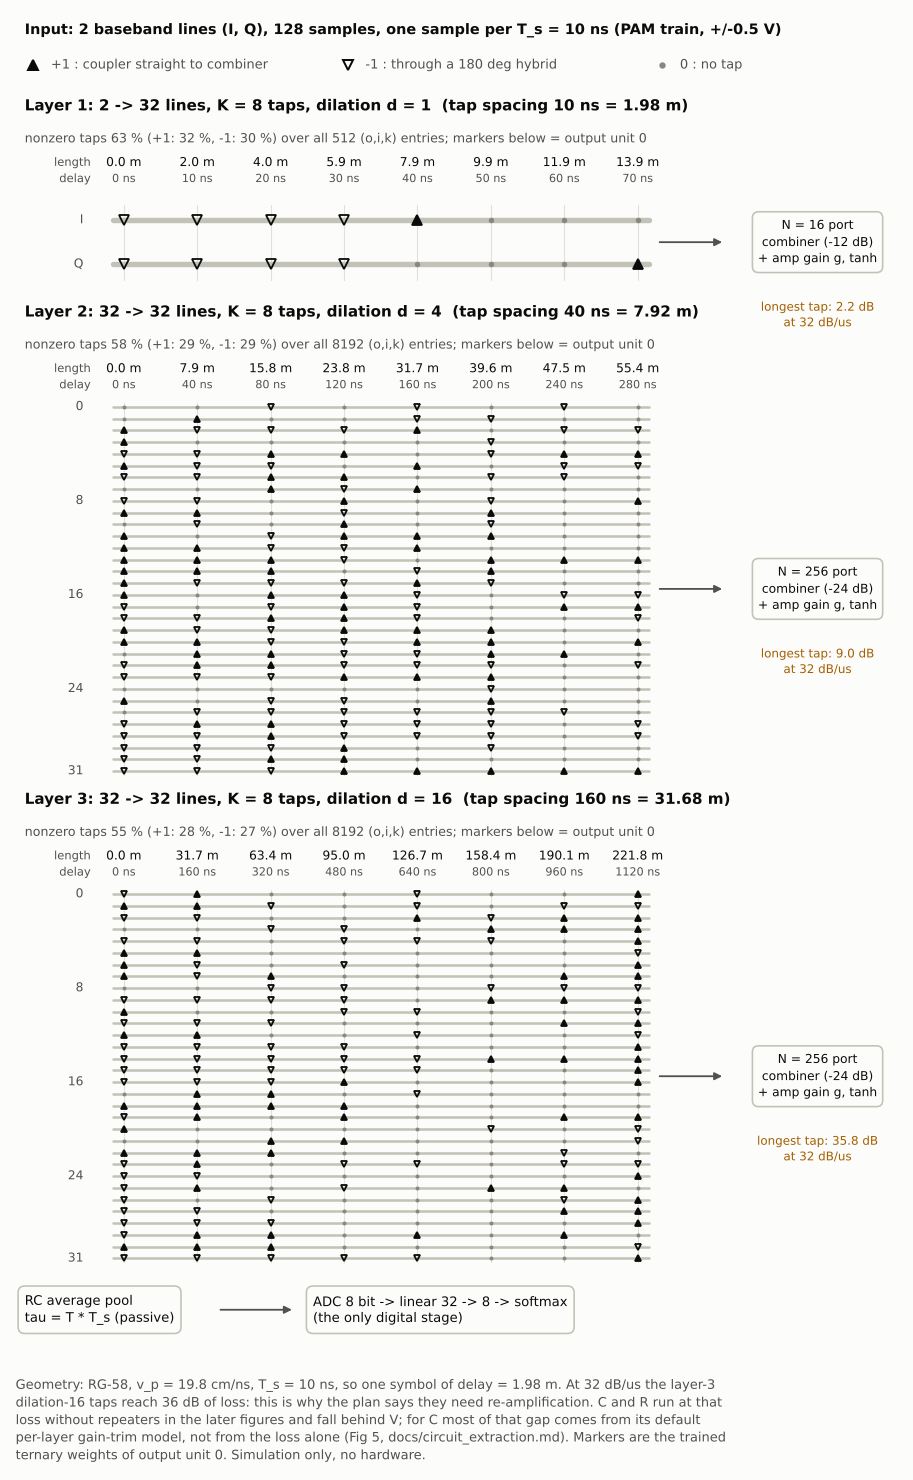

In [5]:
nb.show('fig1_network', run)

## What the tiers agree on (figure 7)

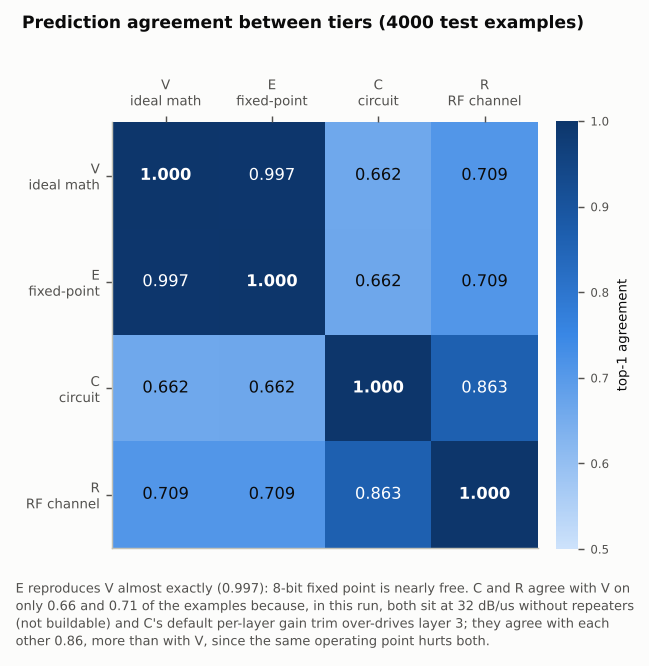

In [6]:
nb.show('fig7_agreement', run)

In [7]:
nb.md(nb.honesty_box(run))

> **What is and is not simulated (read this before the numbers).**
>
> * **Simulation only, synthetic data. No hardware was built or measured.** Coax and transistor models are generic textbook ones (RG-58-like RLC line, generic NPN), not vendor data.
> * **V** = ideal numpy math (the reference). **E** = numpy bit-true fixed point on all 4000 test examples; the Icarus Verilog RTL is bit-compared with it on a subset (first 64 examples, 0 mismatches), the rest is numpy.
> * **C** = ngspice on a layer-1 *unit cell* (per-tap `.ac`, diff-pair `.dc`, `.tran` on 16 examples). **The 4000-example numbers and layers 2-3 come from the circuit-calibrated behavioural model, not from SPICE.**
> * **R** = scikit-rf *channel-level* model (two-port cascades, IFFT, numpy convolution). Not EM, not layout.
> * The float32 baseline is a *reference*, not a tier.
> * **With `--cascade` the R tier uses the line loss that C fitted (32 dB/us, equal to the value put into the netlist) with no repeaters, and C runs at the same loss** (default: one ideal gain trim per layer). That is a far harsher operating point than R's standalone default (5 dB/us), and it is not buildable without repeaters. C/R accuracy of about 0.66/0.70 vs V 0.863 is not a bug: their loss sweeps recover ~0.86 at 0 dB/us. But for C most of the gap is the default per-layer gain trim over-driving layer 3, not line loss (C: 0.663 default, 0.804 with no compensation, 0.805 with ideal per-tap repeaters at 32 dB/us; `docs/circuit_extraction.md`).

## Notebook map

| notebook | what it does | live compute |
|---|---|---|
| 01 task and model | the 8 signal classes, training report, width 8 vs 32, ternary weights | seconds |
| 02 virtual | the ideal forward pass step by step | seconds |
| 03 emulated | fixed-point spec, ADC sweep, RTL vs numpy bit-exact check | ~1 min (iverilog) |
| 04 circuit | the SPICE netlists, live ngspice `.dc` / `.ac` / `.tran`, calibrated vs SPICE | ~1 min (ngspice) |
| 05 rf | scikit-rf line networks, impulse responses, live parameter sweeps | ~2 min |
| 06 compare and LLM | the side-by-side matrix, figures 4-8, the card and the verified commentary | seconds |

Everything heavy (the 10-minute pipeline) is read from `out/<run>/`; change the run with `DLNN_RUN=modrec-w8-full`.